# Laborator 6 · Detectarea anomaliilor
**Dataset:** Online Retail II (UCI) · **Metodologie:** CRISP-DM

| Fază CRISP-DM | Secțiune |
|---|---|
| 1. Înțelegerea sarcinii | 0 |
| 2. Înțelegerea datelor | 2 (grafice, IQR, Z-score) |
| 3. Pregătirea datelor | 3 (tratarea valorilor extreme) |
| 4. Modelare | 4 (punctuale, contextuale, colective) |
| 5. Evaluare | 5 |
| 6. Implementare | 6 (+ pagina Streamlit) |

## 0. Înțelegerea sarcinii (Business understanding)
**Întrebare:** ce **facturi** și ce **clienți** se abat atât de mult de la comportamentul obișnuit încât merită verificați? O anomalie este o observație care „se abate atât de mult de la celelalte încât poate fi generată de alt mecanism”. Cauzele pot fi erori de introducere sau de procesare, dar și cauze **naturale** (ex.: un client angrosist). De aceea o anomalie **nu se șterge automat**: o investigăm. Aplicații tipice: detecția fraudei, a defectelor, a intruziunilor.

**Tipurile pe care le acoperim:**
- **punctuale** (o factură în sine neobișnuită), univariate (o singură variabilă) și multivariate (combinația de variabile);
- **contextuale** (neobișnuită *față de contextul ei*: țara, istoricul clientului);
- **colective** (o perioadă neobișnuită într-o serie de timp: vânzările zilnice).

**Nu avem etichete** (nu știm care facturi „sunt” anomalii), deci nu putem calcula acuratețea. Succesul se judecă astfel:
1. **Acordul între metode independente** (o anomalie reală e prinsă de mai multe metode) și stabilitatea rezultatului la o altă inițializare.
2. **Explicabilitate:** pentru fiecare anomalie spunem *de ce* e neobișnuită.
3. **Un caz cunoscut trebuie găsit:** comanda de 80.995 de bucăți din Laboratorul 1.
4. **Valoarea contextului:** există anomalii pe care contextul le arată și analiza globală nu le vede.

## 1. Setup

In [1]:
import json
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.covariance import EllipticEnvelope
from sklearn.cluster import DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from dateutil.easter import easter
from statsmodels.tsa.statespace.sarimax import SARIMAX

from baza_date import (ARTEFACTE, SEED, construieste_clienti, curata, descrieri_produse, incarca_brut, salveaza_fig, transforma)

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

try:                                   # `display` există în Jupyter/VS Code; în terminal îl înlocuim cu print
    display
except NameError:
    def display(obj):
        print(obj)

CONTAMINARE = 0.01                     # „bugetul de investigare”: cât din observații acceptăm să verificăm manual (1%)

## 2. Înțelegerea datelor (Data understanding)
### 2.1 Încărcare și curățare
Aceeași curățare în straturi ca în Laboratoarele 1–2. Rândurile mutate acolo (servicii, anulări, ajustări) sunt *anomalii de calitate a datelor* deja cunoscute; aici ne ocupăm de ce a rămas în vânzările curate.

In [2]:
df = incarca_brut()
tranzactii, retururi, administrative, ajustari_stoc, contabilitate = curata(df)
contabilitate.to_csv(ARTEFACTE / "curatare.csv", index=False)
clienti, CUTOFF, istoric_v, viitor_v = construieste_clienti(tranzactii, retururi)
display(contabilitate)

,strat,rânduri,% din total
0,1. servicii/taxe/vouchere,5911,0.550
1,2. anulări (C),18286,1.710
2,3. preț/cantitate ≤ 0,6153,0.580
3,rămase: vânzări curate,1037021,97.160


### 2.2 Tabelul de facturi
Unitatea de analiză: **factura** (comanda). Pentru fiecare: câte linii are, câte bucăți, ce valoare totală și ce preț mediu pe bucată. Fără alte variabile, ca fiecare să poată fi introdusă ușor într-un formular (Implementare).

In [3]:
facturi = tranzactii.groupby("Invoice").agg(data=("InvoiceDate", "first"), client=("Customer ID", "first"), tara=("Country", "first"),
                                            nr_linii=("StockCode", "size"), cantitate_totala=("Quantity", "sum"), valoare_totala=("Valoare", "sum"))
facturi["pret_mediu"] = facturi["valoare_totala"] / facturi["cantitate_totala"]
descr = descrieri_produse(tranzactii)
linie_max = tranzactii.loc[tranzactii.groupby("Invoice")["Valoare"].idxmax()].set_index("Invoice")["StockCode"]       # linia cu cea mai mare valoare
facturi["produs_principal"] = linie_max.map(descr).reindex(facturi.index).fillna("(fără descriere)").str.slice(0, 40)
zi = tranzactii.groupby(tranzactii["InvoiceDate"].dt.normalize())["Valoare"].sum()
zi = zi.reindex(pd.date_range(zi.index.min(), zi.index.max(), freq="D"), fill_value=0.0)          # venit zilnic (£), 0 în zilele fără vânzări
NUM_F = ["nr_linii", "cantitate_totala", "valoare_totala", "pret_mediu"]
print(f"Facturi: {len(facturi):,} | cu client: {facturi['client'].notna().mean():.1%}")
display(facturi[NUM_F].describe().T)

Facturi: 39,516 | cu client: 92.6%


,count,mean,std,min,25%,50%,75%,max
nr_linii,"39,516.000",26.243,46.223,1.000,6.000,16.000,29.000,"1,348.000"
cantitate_totala,"39,516.000",288.558,"1,208.173",1.000,69.000,152.000,294.000,"87,167.000"
valoare_totala,"39,516.000",508.912,"1,488.882",0.190,152.550,303.215,496.300,"168,469.600"
pret_mediu,"39,516.000",2.785,11.106,0.040,1.440,1.950,2.821,"1,157.150"


### 2.3 Metode grafice: histogramă, boxplot, scatter / pairs plot
Ce căutăm: coșuri izolate în extremele histogramei, puncte individuale în boxplot, puncte departe de nor în scatter. Folosim și `log1p`, pentru că valorile au coadă lungă.

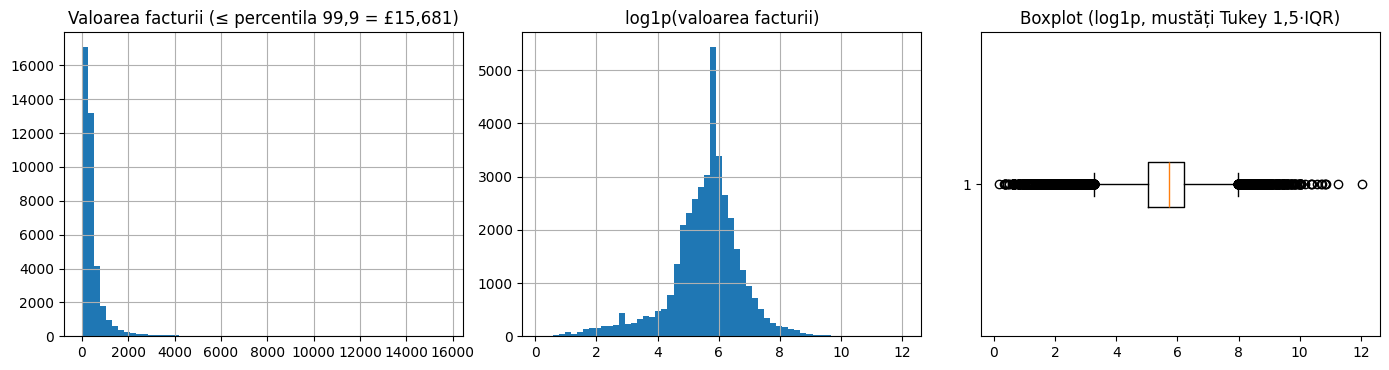

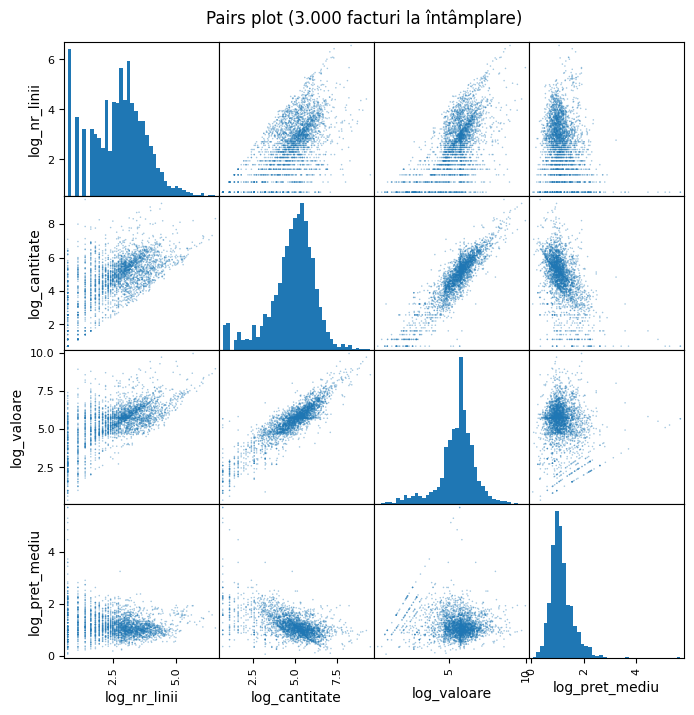

In [4]:
lv = np.log1p(facturi["valoare_totala"])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
p999 = facturi["valoare_totala"].quantile(0.999)
facturi.loc[facturi["valoare_totala"] <= p999, "valoare_totala"].hist(bins=60, ax=ax[0]); ax[0].set_title(f"Valoarea facturii (≤ percentila 99,9 = £{p999:,.0f})")
lv.hist(bins=60, ax=ax[1]); ax[1].set_title("log1p(valoarea facturii)")
ax[2].boxplot(lv, vert=False, whis=1.5); ax[2].set_title("Boxplot (log1p, mustăți Tukey 1,5·IQR)")
plt.tight_layout()
salveaza_fig("lab6_grafice_valoare")

X_log = np.log1p(facturi[["nr_linii", "cantitate_totala", "valoare_totala", "pret_mediu"]].clip(lower=0))
X_log.columns = ["log_nr_linii", "log_cantitate", "log_valoare", "log_pret_mediu"]
esantion = X_log.sample(min(3000, len(X_log)), random_state=SEED)
pd.plotting.scatter_matrix(esantion, figsize=(8, 8), diagonal="hist", s=5, alpha=0.4, hist_kwds={"bins": 40})
plt.suptitle("Pairs plot (3.000 facturi la întâmplare)", y=0.92)
salveaza_fig("lab6_pairs")

### 2.4 Metode statistice: IQR și Z-score
- **IQR (Tukey):** anomalie dacă valoarea e în afara `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`.
- **Z-score:** anomalie dacă `|z| > 3`.
Le aplicăm pe valoarea facturii, brută și după `log1p`. Z-score pe date foarte asimetrice „se maschează”: media și abaterea standard sunt trase de extreme, deci se detectează mai puține.

In [5]:
def univariat(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    jos, sus = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return pd.Series({"limita jos (IQR)": jos, "limita sus (IQR)": sus, "anomalii IQR": int(((s < jos) | (s > sus)).sum()),
                      "anomalii Z>3": int((z.abs() > 3).sum()), "% IQR": ((s < jos) | (s > sus)).mean() * 100, "% Z>3": (z.abs() > 3).mean() * 100})


univ = pd.DataFrame({"valoare brută (£)": univariat(facturi["valoare_totala"]), "log1p(valoare)": univariat(lv)})
univ.to_csv(ARTEFACTE / "lab6_univariat.csv")
display(univ)

print("Cele mai mari 8 facturi după valoare (le inspectăm: sunt reale sau erori?):")
mari = facturi.nlargest(8, "valoare_totala")[["data", "client", "tara", "produs_principal", "nr_linii", "cantitate_totala", "valoare_totala", "pret_mediu"]]
mari["client"] = mari["client"].fillna("anonim")
mari.to_csv(ARTEFACTE / "lab6_cele_mai_mari.csv")
display(mari)

,valoare brută (£),log1p(valoare)
limita jos (IQR),-363.075,3.271
limita sus (IQR),"1,011.925",7.972
anomalii IQR,"3,457.000","2,948.000"
anomalii Z>3,288.000,683.000
% IQR,8.748,7.460
% Z>3,0.729,1.728


Cele mai mari 8 facturi după valoare (le inspectăm: sunt reale sau erori?):


,data,client,tara,produs_principal,nr_linii,cantitate_totala,valoare_totala,pret_mediu
Invoice,,,,,,,,
581483,2011-12-09 09:15:00,16446,United Kingdom,"PAPER CRAFT , LITTLE BIRDIE",1,80995,"168,469.600",2.080
541431,2011-01-18 10:01:00,12346,United Kingdom,MEDIUM CERAMIC TOP STORAGE JAR,1,74215,"77,183.600",1.040
574941,2011-11-07 17:42:00,anonim,United Kingdom,SMALL POPCORN HOLDER,101,14149,"52,940.940",3.742
576365,2011-11-14 17:55:00,anonim,United Kingdom,PAPER CHAIN KIT 50'S CHRISTMAS,99,13956,"50,653.910",3.630
533027,2010-11-15 16:02:00,anonim,United Kingdom,PAPER CHAIN KIT 50'S CHRISTMAS,111,13387,"49,844.990",3.723
531516,2010-11-08 16:45:00,anonim,United Kingdom,PAPER CHAIN KIT 50'S CHRISTMAS,115,12410,"45,332.970",3.653
493819,2010-01-07 12:34:00,14156,EIRE,POLKADOT CUTLERY 24 PCS IN TRAY,94,25018,"44,051.600",1.761
556444,2011-06-10 15:28:00,15098,United Kingdom,PICNIC BASKET WICKER SMALL,1,60,"38,970.000",649.500


## 3. Pregătirea datelor (Data preparation)
### 3.1 Cum tratăm valorile extreme?
Variante uzuale: ștergere, trunchiere, winsorizare, transformare logaritmică / Z-score, „cap and floor”. Comparăm efectul fiecăreia asupra valorii facturii (număr de rânduri, medie, abatere standard, asimetrie, maxim).
**Decizie pentru acest laborator:** *nu* tratăm extremele, pentru că ele sunt exact ținta detecției. Tratarea (de obicei `log1p` sau winsorizare) ar fi pasul potrivit **înainte de un model predictiv**, ca cel din Laboratorul 1. Pentru detecție, `log1p` e singura transformare folosită (stabilizează scara).

In [6]:
s = facturi["valoare_totala"]
q1, q3 = s.quantile([0.25, 0.75])
jos, sus = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
p1, p99 = s.quantile([0.01, 0.99])
variante = {
    "originală": s,
    "ștergere (în afara fences IQR)": s[(s >= jos) & (s <= sus)],
    "trunchiere (scoatem 1% din fiecare capăt)": s[(s >= p1) & (s <= p99)],
    "winsorizare (limităm la percentilele 1–99)": s.clip(p1, p99),
    "cap and floor (limităm la fences IQR)": s.clip(jos, sus),
    "transformare log1p": np.log1p(s),
    "standardizare Z-score": (s - s.mean()) / s.std(),
}
tratari = pd.DataFrame({n: {"rânduri": len(v), "medie": v.mean(), "abatere standard": v.std(), "asimetrie": v.skew(), "maxim": v.max()}
                        for n, v in variante.items()}).T
tratari.to_csv(ARTEFACTE / "lab6_tratari.csv")
display(tratari)

,rânduri,medie,abatere standard,asimetrie,maxim
originală,"39,516.000",508.912,"1,488.882",48.196,"168,469.600"
ștergere (în afara fences IQR),"36,059.000",308.205,219.844,0.939,"1,011.670"
trunchiere (scoatem 1% din fiecare capăt),"38,737.000",425.840,492.172,3.445,"4,171.410"
winsorizare (limităm la percentilele 1–99),"39,516.000",459.317,615.516,3.823,"4,174.155"
cap and floor (limităm la fences IQR),"39,516.000",369.769,289.202,0.989,"1,011.925"
transformare log1p,"39,516.000",5.557,1.204,-0.768,12.035
standardizare Z-score,"39,516.000",0.000,1.000,48.196,112.810


### 3.2 Matricele de lucru
- **Facturi:** `log1p` pe numărul de linii, cantitate, valoare, preț mediu; apoi `StandardScaler` (metodele pe distanțe sunt sensibile la scară).
- **Clienți:** variabilele finale din Laboratoarele 1–2 (fără indicatorul `uk`, care e binar), standardizate.

In [7]:
scaler_f = StandardScaler().fit(X_log)
Zf = scaler_f.transform(X_log)

cl_x = transforma(clienti)
FEAT_CL = ["recenta_zile", "vechime_zile", "rata_retur", "log_frecventa", "log_produse_distincte", "log_vanzari_ultimele_90z",
           "log_valoare_medie_factura", "log_retururi"]
Zc = StandardScaler().fit_transform(cl_x[FEAT_CL])
print("Facturi:", Zf.shape, "| clienți:", Zc.shape)

Facturi: (39516, 4) | clienți: (5256, 8)


## 4. Modelare (Modeling)
### 4.1 Anomalii punctuale multivariate: șase metode independente
Toate primesc același „buget” de **1%** (`contamination`), ca să le putem compara, cu excepția DBSCAN, care își stabilește singur numărul de puncte de zgomot.
- **Isolation Forest:** izolează observațiile cu split-uri aleatoare; anomaliile se izolează în puține split-uri (căi scurte).
- **LOF:** compară densitatea locală a unui punct cu cea a vecinilor lui; densitate mult mai mică = anomalie.
- **DBSCAN:** punctele care nu aparțin niciunui cluster (zgomot, −1). ε din graficul k-distanță (cotul curbei), `min_samples = 2 · nr. variabile`, ca în Laboratorul 3.
- **One-Class SVM** (familia modelelor liniare/kernel din PyOD): învață frontiera zonei „normale”; nu se antrenează pe toate punctele (e lent), ci pe 5.000 alese la întâmplare, apoi scorează tot.
- **MCD (Minimum Covariance Determinant, `EllipticEnvelope`)**: distanța Mahalanobis față de o elipsă robustă; anomalie = departe de elipsă.
- **kNN:** distanța la al 10-lea vecin; anomalie = cele mai mari 1%.

In [8]:
def cot(y):
    """Punctul curbei cel mai îndepărtat de dreapta dintre primul și ultimul punct (metoda „kneedle” simplificată)."""
    x = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min())
    return int(np.argmax(np.abs(yn - x)))


def detecteaza(Z, contaminare=CONTAMINARE, seed=SEED):
    """Rulează cele șase metode pe o matrice standardizată. Întoarce (steaguri bool, scoruri; scor mare = mai anormal)."""
    rng = np.random.default_rng(seed)
    Zj = Z + rng.normal(0, 1e-4, Z.shape)                 # zgomot minuscul: duplicatele exacte strică LOF și kNN
    steag, scor = {}, {}

    iso = IsolationForest(n_estimators=300, contamination=contaminare, random_state=seed).fit(Z)
    steag["Isolation Forest"], scor["Isolation Forest"] = iso.predict(Z) == -1, -iso.score_samples(Z)

    lof = LocalOutlierFactor(n_neighbors=20, contamination=contaminare)
    steag["LOF"] = lof.fit_predict(Zj) == -1
    scor["LOF"] = -lof.negative_outlier_factor_

    min_s = 2 * Z.shape[1]
    kd_pe_punct = NearestNeighbors(n_neighbors=min_s).fit(Z).kneighbors(Z)[0][:, -1]   # distanța la al min_s-lea vecin
    kd = np.sort(kd_pe_punct)
    eps = float(kd[cot(kd)])
    et = DBSCAN(eps=eps, min_samples=min_s).fit_predict(Z)
    steag["DBSCAN"] = et == -1
    scor["DBSCAN"] = kd_pe_punct

    sub = rng.choice(len(Z), size=min(5000, len(Z)), replace=False)
    svm = OneClassSVM(nu=contaminare, kernel="rbf", gamma="scale").fit(Z[sub])
    steag["One-Class SVM"], scor["One-Class SVM"] = svm.predict(Z) == -1, -svm.decision_function(Z)

    mcd = EllipticEnvelope(contamination=contaminare, random_state=seed).fit(Z)
    steag["MCD (elipsă robustă)"], scor["MCD (elipsă robustă)"] = mcd.predict(Z) == -1, mcd.mahalanobis(Z)

    knn = NearestNeighbors(n_neighbors=11).fit(Zj)
    d10 = knn.kneighbors(Zj)[0][:, -1]
    steag["kNN (distanța la al 10-lea vecin)"], scor["kNN (distanța la al 10-lea vecin)"] = d10 >= np.quantile(d10, 1 - contaminare), d10
    return pd.DataFrame(steag), pd.DataFrame(scor), eps


steag_f, scor_f, eps_f = detecteaza(Zf)
steag_f.index = scor_f.index = facturi.index
METODE = list(steag_f.columns)
steag_f["nr_metode"] = steag_f[METODE].sum(axis=1)
print(f"ε DBSCAN (cotul graficului k-distanță) = {eps_f:.3f}")
sumar_f = pd.DataFrame({"anomalii": steag_f[METODE].sum(), "% din facturi": steag_f[METODE].mean() * 100})
display(sumar_f)

ε DBSCAN (cotul graficului k-distanță) = 0.356


,anomalii,% din facturi
Isolation Forest,394,0.997
LOF,396,1.002
DBSCAN,499,1.263
One-Class SVM,646,1.635
MCD (elipsă robustă),396,1.002
kNN (distanța la al 10-lea vecin),396,1.002


### 4.2 Anomalii punctuale la nivel de client
Aceeași procedură pe tabelul de clienți (8 variabile din Laboratoarele 1–2).

In [9]:
steag_c, scor_c, eps_c = detecteaza(Zc)
steag_c.index = scor_c.index = clienti.index
steag_c["nr_metode"] = steag_c[METODE].sum(axis=1)
sumar_c = pd.DataFrame({"anomalii": steag_c[METODE].sum(), "% din clienți": steag_c[METODE].mean() * 100})
display(sumar_c)

,anomalii,% din clienți
Isolation Forest,53,1.008
LOF,53,1.008
DBSCAN,141,2.683
One-Class SVM,64,1.218
MCD (elipsă robustă),53,1.008
kNN (distanța la al 10-lea vecin),53,1.008


### 4.3 Anomalii contextuale
Definim un **context** prin atribute contextuale și testăm dacă observația e anormală **față de context**, cu atribute comportamentale (aici: valoarea facturii, `log1p`). Folosim tehnica *reducerii la anomalii punctuale*: segmentăm după context și aplicăm Z-score în fiecare segment.
- **Context 1 · țara** (context de profil): Z-score în fiecare țară cu cel puțin 200 de facturi.
- **Context 2 · clientul însuși**: valoarea facturii față de **celelalte** facturi ale aceluiași client (leave-one-out, ca factura testată să nu-și influențeze propria medie), pentru clienți cu cel puțin 8 facturi. Abaterea standard minimă e 0,2 pe scara log (~20%), ca un client cu comenzi aproape identice să nu producă Z uriaș din variații minuscule.
Comparăm cu varianta **globală** (Z-score pe toate facturile): câte anomalii vede contextul și analiza globală nu?

In [10]:
CTX = pd.DataFrame({"lv": lv, "tara": facturi["tara"], "client": facturi["client"]})
z_global = (CTX["lv"] - CTX["lv"].mean()) / CTX["lv"].std()

nr_tara = CTX["tara"].map(CTX["tara"].value_counts())
mare = nr_tara >= 200
grp = CTX[mare].groupby("tara")["lv"]
z_tara = ((CTX.loc[mare, "lv"] - grp.transform("mean")) / grp.transform("std")).reindex(CTX.index)

c = CTX[CTX["client"].notna()].copy()
n = c.groupby("client")["lv"].transform("size")
sum_, sum2 = c.groupby("client")["lv"].transform("sum"), (c["lv"] ** 2).groupby(c["client"]).transform("sum")
med_alt = (sum_ - c["lv"]) / (n - 1)
var_alt = ((sum2 - c["lv"] ** 2) - (n - 1) * med_alt ** 2) / (n - 2)
z_client = ((c["lv"] - med_alt) / np.sqrt(var_alt.clip(lower=0.2 ** 2))).where(n >= 8).reindex(CTX.index)

ctx_rez = pd.DataFrame({"facturi evaluate": [int(z_global.notna().sum()), int(z_tara.notna().sum()), int(z_client.notna().sum())],
                        "anomalii |z| > 3": [int((z_global.abs() > 3).sum()), int((z_tara.abs() > 3).sum()), int((z_client.abs() > 3).sum())]},
                       index=["global (toate facturile)", "context: țara", "context: clientul însuși"])
ctx_rez["% din evaluate"] = ctx_rez["anomalii |z| > 3"] / ctx_rez["facturi evaluate"] * 100
glob = z_global.abs() > 3
ctx_rez["din care NEvăzute de analiza globală"] = [0, int(((z_tara.abs() > 3) & ~glob).sum()), int(((z_client.abs() > 3) & ~glob).sum())]
ctx_rez.to_csv(ARTEFACTE / "lab6_contextuale.csv")
display(ctx_rez)

ctxa = facturi.assign(z_global=z_global, z_tara=z_tara, z_client=z_client)
ctxa = ctxa[(ctxa["z_client"].abs() > 3) & ~glob]
ctxa["client"] = ctxa["client"].fillna("anonim")
ctxa = ctxa.reindex(ctxa["z_client"].abs().sort_values(ascending=False).index)
print("Facturi anormale doar în contextul clientului (cele mai puternice 10):")
display(ctxa.head(10)[["client", "produs_principal", "nr_linii", "cantitate_totala", "valoare_totala", "z_global", "z_client"]])
ctxa.head(200).reset_index().to_csv(ARTEFACTE / "lab6_contextuale_facturi.csv", index=False)

,facturi evaluate,anomalii |z| > 3,% din evaluate,din care NEvăzute de analiza globală
global (toate facturile),39516,683,1.728,0
context: țara,38332,623,1.625,23
context: clientul însuși,24184,712,2.944,618


Facturi anormale doar în contextul clientului (cele mai puternice 10):


,client,produs_principal,nr_linii,cantitate_totala,valoare_totala,z_global,z_client
Invoice,,,,,,,
527962,13426,TEA TIME OVEN GLOVE,1,8,8.480,-2.747,-15.626
517757,13647,VINTAGE CREAM 3 BASKET CAKE STAND,1,2,19.900,-2.091,-15.127
517097,17612,BLACK HEART CARD HOLDER,1,4,15.800,-2.272,-14.667
544423,12553,RETRO PLASTIC POLKA TRAY,1,15,6.300,-2.964,-13.862
524417,16177,HEART OF WICKER SMALL,1,12,19.800,-2.095,-13.600
550824,18177,SKULL SHOULDER BAG,1,5,8.250,-2.768,-13.554
580302,16103,RECYCLED ACAPULCO MAT TURQUOISE,1,2,16.500,-2.238,-13.525
512605,14978,PICNIC BASKET WICKER SMALL,1,2,8.500,-2.745,-13.513
524262,14625,DOORMAT MERRY CHRISTMAS RED,1,2,15.900,-2.267,-12.878


### 4.4 Anomalii colective: serie de timp (ARIMA sezonier cu variabile de calendar)
O **zi** poate fi neobișnuită chiar dacă nicio factură din ea nu e. Modelăm vânzările zilnice ca serie de timp; zilele care se abat mult de la predicție sunt anomalii, iar zilele anormale consecutive **de același sens** formează un **episod** (anomalie colectivă).
- Serie: venitul zilnic (£), cu zile fără vânzări = 0, pe scara `log1p`.
- Model: **ARIMA cu componentă sezonieră de 7 zile** (săptămâna are un tipar clar, ex.: zile fără vânzări) **plus două variabile de calendar cunoscute dinainte**: sărbătorile legale din Marea Britanie (calculate din regulă, inclusiv Paștele) și perioada de sărbători de iarnă (24 dec. – 2 ian.). Fără ele, modelul ar marca drept „anomalii" exact zilele libere, adică abateri previzibile; comparăm ambele variante.
- Ordinul se alege după **AIC** (mai mic = mai bun), dintre câteva variante.
- Anomalie: **Z robust** al reziduului `(r − mediana) / (1,4826 · MAD)` cu `|z| > 3`, calculat după primele 14 zile (cât durează modelul să se „încălzească"). Varianta robustă nu e trasă în sus de chiar zilele pe care vrem să le găsim.

Zile marcate în calendar: {'sarbatoare_UK': 11, 'sarbatori_iarna': 20}


,"ordin (p,d,q)",calendar,AIC,BIC,zile anormale (|z| > 3)
model,,,,,
"(1, 0, 1) fără calendar","(1, 0, 1)",nu,"2,966.940","2,989.966",56
"(1, 0, 1) cu calendar","(1, 0, 1)",da,"2,290.634","2,322.871",56
"(2, 0, 1) fără calendar","(2, 0, 1)",nu,"2,960.459","2,988.091",55
"(2, 0, 1) cu calendar","(2, 0, 1)",da,"2,286.238","2,323.080",47
"(1, 1, 1) fără calendar","(1, 1, 1)",nu,"2,993.472","3,016.492",65
"(1, 1, 1) cu calendar","(1, 1, 1)",da,"2,283.339","2,315.567",44
"(2, 1, 1) fără calendar","(2, 1, 1)",nu,"2,986.152","3,013.775",71
"(2, 1, 1) cu calendar","(2, 1, 1)",da,"2,284.642","2,321.474",40


Model ales (AIC minim, cu calendar): (1, 1, 1) cu calendar | zile anormale aceleași ordin fără calendar: 65
Zile evaluate: 725 | zile anormale: 44 (6.1%) | episoade: 33


,inceput,sfarsit,zile anormale,venit mediu (£),prezis mediu (£),sens
0,2009-12-19,2009-12-19,1,0.000,76.715,sub predicție
1,2009-12-26,2009-12-26,1,0.000,0.000,sub predicție
2,2009-12-28,2009-12-28,1,0.000,3.224,sub predicție
3,2010-01-02,2010-01-02,1,0.000,0.000,sub predicție
4,2010-01-03,2010-01-03,1,0.000,"2,932.102",sub predicție
5,2010-01-05,2010-01-08,3,"32,322.368","3,413.565",peste predicție
6,2010-01-09,2010-01-09,1,0.000,51.319,sub predicție
7,2010-01-10,2010-01-12,3,"32,644.953","3,362.665",peste predicție
8,2010-01-16,2010-01-16,1,0.000,28.809,sub predicție
9,2010-01-17,2010-01-17,1,"17,578.240","1,231.513",peste predicție


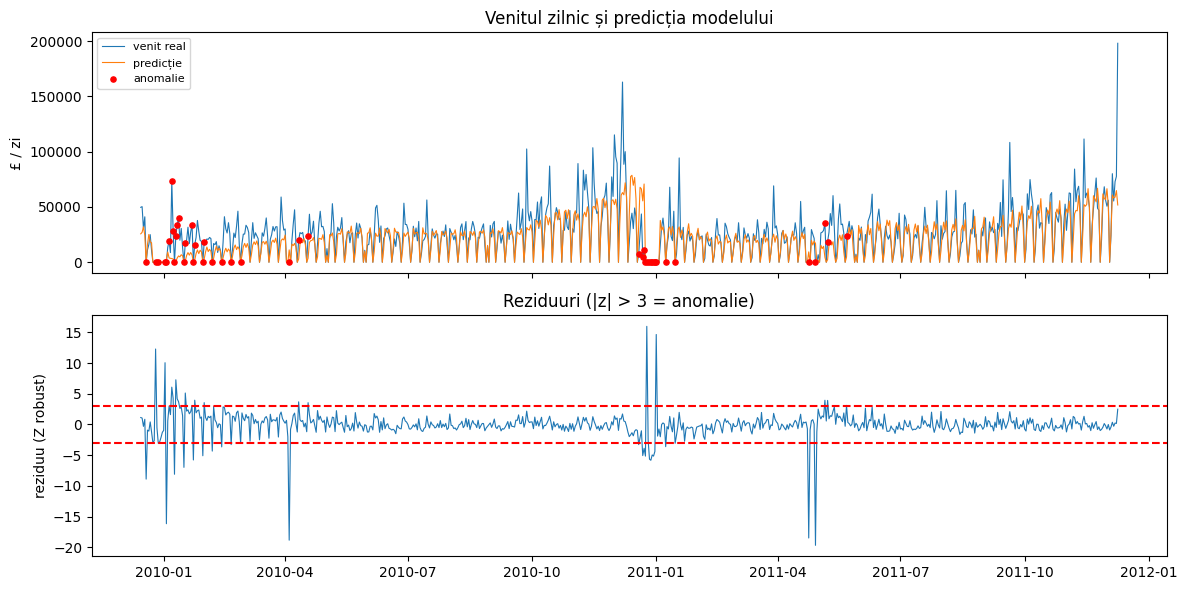

In [11]:
y = np.log1p(zi)
y.index.freq = "D"


def sarbatori_uk(ani):
    """Sărbători legale UK (Anglia): 1 ian., Vinerea Mare, Lunea Paștelui, prima luni din mai, ultima luni din mai și din august,
    25 și 26 dec.; când pică în weekend se adaugă și prima zi lucrătoare liberă."""
    zile = set()
    for a in ani:
        paste = pd.Timestamp(easter(a))
        zile |= {pd.Timestamp(a, 1, 1), paste - pd.Timedelta(days=2), paste + pd.Timedelta(days=1), pd.Timestamp(a, 12, 25), pd.Timestamp(a, 12, 26)}
        mai = pd.date_range(f"{a}-05-01", f"{a}-05-31", freq="W-MON")
        aug = pd.date_range(f"{a}-08-01", f"{a}-08-31", freq="W-MON")
        zile |= {mai[0], mai[-1], aug[-1]}
        for d in [pd.Timestamp(a, 1, 1), pd.Timestamp(a, 12, 25), pd.Timestamp(a, 12, 26)]:
            if d.weekday() >= 5:
                s = d + pd.Timedelta(days=1)
                while s.weekday() >= 5 or s in zile:
                    s += pd.Timedelta(days=1)
                zile.add(s)
    return zile


iarna = ((y.index.month == 12) & (y.index.day >= 24)) | ((y.index.month == 1) & (y.index.day <= 2))
X_cal = pd.DataFrame({"sarbatoare_UK": (y.index.isin(list(sarbatori_uk(range(y.index.year.min(), y.index.year.max() + 1)))) & ~iarna).astype(float),
                      "sarbatori_iarna": iarna.astype(float)}, index=y.index)
print("Zile marcate în calendar:", X_cal.sum().astype(int).to_dict())


def z_robust(r):
    med = r.median()
    return (r - med) / (1.4826 * (r - med).abs().median())


def potriveste(ordin, calendar):
    return SARIMAX(y, exog=X_cal if calendar else None, order=ordin, seasonal_order=(1, 0, 1, 7)).fit(disp=False, maxiter=200)


modele, rez_arima = {}, []
for ordin in [(1, 0, 1), (2, 0, 1), (1, 1, 1), (2, 1, 1)]:
    for calendar in [False, True]:
        r = potriveste(ordin, calendar)
        nume_m = f"{ordin} {'cu' if calendar else 'fără'} calendar"
        modele[nume_m] = (r, ordin, calendar)
        rez_arima.append({"model": nume_m, "ordin (p,d,q)": str(ordin), "calendar": "da" if calendar else "nu", "AIC": r.aic, "BIC": r.bic,
                          "zile anormale (|z| > 3)": int((z_robust((y - r.fittedvalues).iloc[14:]).abs() > 3).sum())})
rez_arima = pd.DataFrame(rez_arima).set_index("model")
rez_arima.to_csv(ARTEFACTE / "lab6_arima.csv")
display(rez_arima)
cu_cal = rez_arima[rez_arima["calendar"] == "da"]
nume_best = cu_cal["AIC"].idxmin()
best, best_ordin, _ = modele[nume_best]
fara_cal = rez_arima[(rez_arima["calendar"] == "nu") & (rez_arima["ordin (p,d,q)"] == str(best_ordin))]
ZILE_FARA_CAL = int(fara_cal["zile anormale (|z| > 3)"].iloc[0])
print("Model ales (AIC minim, cu calendar):", nume_best, "| zile anormale aceleași ordin fără calendar:", ZILE_FARA_CAL)

prezis = best.fittedvalues
rez = (y - prezis).iloc[14:]
z_zi = z_robust(rez)
serie = pd.DataFrame({"venit": zi.iloc[14:], "prezis": np.expm1(prezis.iloc[14:]).clip(lower=0), "z": z_zi, "anomalie": z_zi.abs() > 3})
serie["zi_saptamana"] = serie.index.day_name()
serie["calendar"] = np.where(X_cal.loc[serie.index, "sarbatori_iarna"] > 0, "sărbători de iarnă", np.where(X_cal.loc[serie.index, "sarbatoare_UK"] > 0, "sărbătoare legală", ""))
serie.index.name = "data"
serie.reset_index().to_csv(ARTEFACTE / "lab6_serie_zilnica.csv", index=False)

# episoade: zile anormale apropiate (cel mult o zi între ele), de același sens (peste / sub predicție)
a = serie[serie["anomalie"]]
nou = (a.index.to_series().diff().dt.days.fillna(99) > 2) | (np.sign(a["z"]).diff().fillna(1) != 0)
grup = nou.cumsum().to_numpy()
episoade = pd.DataFrame({"inceput": [g.index.min() for _, g in a.groupby(grup)], "sfarsit": [g.index.max() for _, g in a.groupby(grup)]})
if len(episoade):
    episoade["zile anormale"] = [int(len(g)) for _, g in a.groupby(grup)]
    episoade["venit mediu (£)"] = [serie.loc[s:e, "venit"].mean() for s, e in zip(episoade["inceput"], episoade["sfarsit"])]
    episoade["prezis mediu (£)"] = [serie.loc[s:e, "prezis"].mean() for s, e in zip(episoade["inceput"], episoade["sfarsit"])]
    episoade["sens"] = np.where(episoade["venit mediu (£)"] > episoade["prezis mediu (£)"], "peste predicție", "sub predicție")
episoade.to_csv(ARTEFACTE / "lab6_episoade.csv", index=False)
print(f"Zile evaluate: {len(serie)} | zile anormale: {int(serie['anomalie'].sum())} ({serie['anomalie'].mean():.1%}) | episoade: {len(episoade)}")
display(episoade)

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(serie.index, serie["venit"], lw=0.8, label="venit real"); ax[0].plot(serie.index, serie["prezis"], lw=0.8, label="predicție")
ax[0].scatter(serie.index[serie["anomalie"]], serie.loc[serie["anomalie"], "venit"], color="red", s=14, label="anomalie", zorder=3)
ax[0].set_ylabel("£ / zi"); ax[0].legend(fontsize=8); ax[0].set_title("Venitul zilnic și predicția modelului")
ax[1].plot(serie.index, serie["z"], lw=0.8); ax[1].axhline(3, color="r", ls="--"); ax[1].axhline(-3, color="r", ls="--")
ax[1].set_ylabel("reziduu (Z robust)"); ax[1].set_title("Reziduuri (|z| > 3 = anomalie)")
plt.tight_layout()
salveaza_fig("lab6_serie_zilnica")

## 5. Evaluare (Evaluation)
### 5.1 Acordul dintre metode
Fără etichete, „cât de bune sunt metodele” se vede din **cât se suprapun** (Jaccard = intersecție / reuniune; 1 = aceleași puncte) și din **stabilitate**: rulăm Isolation Forest cu 5 inițializări diferite și măsurăm cât din cele 1% se repetă.

,Isolation Forest,LOF,DBSCAN,One-Class SVM,MCD (elipsă robustă),kNN (distanța la al 10-lea vecin)
Isolation Forest,1.000,0.105,0.205,0.169,0.246,0.264
LOF,0.105,1.000,0.119,0.140,0.076,0.151
DBSCAN,0.205,0.119,1.000,0.262,0.195,0.636
One-Class SVM,0.169,0.140,0.262,1.000,0.173,0.311
MCD (elipsă robustă),0.246,0.076,0.195,0.173,1.000,0.205
kNN (distanța la al 10-lea vecin),0.264,0.151,0.636,0.311,0.205,1.000


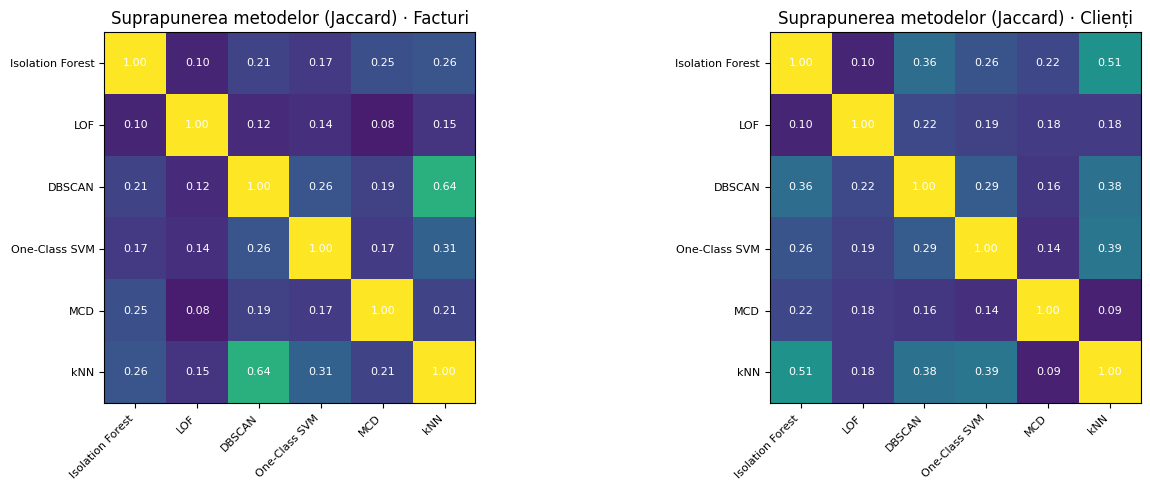

Stabilitatea Isolation Forest la 5 inițializări (Jaccard mediu): 0.739


,facturi,clienți
nr. metode care o marchează,,
0,38065,5055
1,833,104
2,259,28
3,162,36
4,109,22
5,74,5
6,14,6


In [12]:
def jaccard(steag):
    m = steag.columns
    return pd.DataFrame([[(steag[a] & steag[b]).sum() / max((steag[a] | steag[b]).sum(), 1) for b in m] for a in m], index=m, columns=m)


jac_f, jac_c = jaccard(steag_f[METODE]), jaccard(steag_c[METODE])
jac_f.to_csv(ARTEFACTE / "lab6_jaccard_facturi.csv"); jac_c.to_csv(ARTEFACTE / "lab6_jaccard_clienti.csv")
display(jac_f)

SCURT = {"Isolation Forest": "Isolation Forest", "LOF": "LOF", "DBSCAN": "DBSCAN", "One-Class SVM": "One-Class SVM",
         "MCD (elipsă robustă)": "MCD", "kNN (distanța la al 10-lea vecin)": "kNN"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (j, t) in zip(ax, [(jac_f, "Facturi"), (jac_c, "Clienți")]):
    im = a.imshow(j, vmin=0, vmax=1, cmap="viridis")
    a.set_xticks(range(len(j))); a.set_xticklabels([SCURT[c] for c in j.columns], rotation=45, ha="right", fontsize=8)
    a.set_yticks(range(len(j))); a.set_yticklabels([SCURT[c] for c in j.index], fontsize=8)
    for i in range(len(j)):
        for k in range(len(j)):
            a.text(k, i, f"{j.iloc[i, k]:.2f}", ha="center", va="center", fontsize=8, color="w")
    a.set_title(f"Suprapunerea metodelor (Jaccard) · {t}")
plt.tight_layout()
salveaza_fig("lab6_jaccard")

seturi_seed = [set(facturi.index[IsolationForest(n_estimators=300, contamination=CONTAMINARE, random_state=sd).fit(Zf).predict(Zf) == -1]) for sd in range(5)]
stab = np.mean([len(a & b) / len(a | b) for i, a in enumerate(seturi_seed) for b in seturi_seed[i + 1:]])
print(f"Stabilitatea Isolation Forest la 5 inițializări (Jaccard mediu): {stab:.3f}")

distr = pd.DataFrame({"facturi": steag_f["nr_metode"].value_counts().sort_index(), "clienți": steag_c["nr_metode"].value_counts().sort_index()}).fillna(0).astype(int)
distr.index.name = "nr. metode care o marchează"
distr.to_csv(ARTEFACTE / "lab6_consens.csv")
display(distr)

### 5.2 Anomaliile de consens și explicația lor
**Regulă de consens:** o factură/un client e *anomalie de consens* dacă e marcat de **cel puțin 3 din cele 6 metode** (jumătate).
**Explicația** vine din date: pentru fiecare variabilă calculăm un Z robust (`(x − mediana) / (1,4826 · MAD)`, rezistent la extreme) și spunem care variabile se abat cel mai mult și în ce sens.

In [13]:
PRAG_CONSENS = 3


def explica(X, nume_afisat, k=2):
    """Pentru fiecare rând, textul cu cele k variabile cu cel mai mare |Z robust|."""
    med = X.median()
    mad = (X - med).abs().median() * 1.4826
    z = (X - med) / mad.where(mad > 0, X.std())
    sus = np.argsort(-z.abs().to_numpy(), axis=1)[:, :k]
    text = ["; ".join(f"{nume_afisat[X.columns[j]]} {'↑' if z.iloc[i, j] > 0 else '↓'} (z = {z.iloc[i, j]:+.1f})" for j in row) for i, row in enumerate(sus)]
    return pd.Series(text, index=X.index), z


nume_f = {"log_nr_linii": "nr. linii", "log_cantitate": "cantitate", "log_valoare": "valoare", "log_pret_mediu": "preț mediu"}
expl_f, z_f = explica(X_log, nume_f)
cons_f = steag_f["nr_metode"] >= PRAG_CONSENS
top_f = facturi.assign(nr_metode=steag_f["nr_metode"], scor_IF=scor_f["Isolation Forest"], explicatie=expl_f)[cons_f].sort_values(["nr_metode", "scor_IF"], ascending=False)
top_f = top_f.assign(client=top_f["client"].fillna("anonim"))
top_f.drop(columns=["scor_IF"]).head(300).reset_index().to_csv(ARTEFACTE / "lab6_anomalii_facturi.csv", index=False)
print(f"Facturi de consens (≥ {PRAG_CONSENS} metode): {int(cons_f.sum())} din {len(facturi):,} ({cons_f.mean():.2%})")
display(top_f.head(12)[["data", "client", "produs_principal", "nr_linii", "cantitate_totala", "valoare_totala", "pret_mediu", "nr_metode", "explicatie"]])

cand = clienti.assign(nr_metode=steag_c["nr_metode"], scor_IF=scor_c["Isolation Forest"])
expl_c, _ = explica(cl_x[FEAT_CL], {c: c.replace("log_", "") for c in FEAT_CL})
cand["explicatie"] = expl_c
cons_c = cand["nr_metode"] >= PRAG_CONSENS
top_c = cand[cons_c].sort_values(["nr_metode", "scor_IF"], ascending=False)
top_c[["recenta_zile", "frecventa", "vanzari_brute", "valoare_medie_factura", "retururi_val", "nr_metode", "explicatie"]].head(200).reset_index().to_csv(ARTEFACTE / "lab6_anomalii_clienti.csv", index=False)
print(f"Clienți de consens (≥ {PRAG_CONSENS} metode): {int(cons_c.sum())} din {len(clienti):,} ({cons_c.mean():.2%})")
display(top_c.head(10)[["recenta_zile", "frecventa", "vanzari_brute", "valoare_medie_factura", "nr_metode", "explicatie"]])

Facturi de consens (≥ 3 metode): 359 din 39,516 (0.91%)


,data,client,produs_principal,nr_linii,cantitate_totala,valoare_totala,pret_mediu,nr_metode,explicatie
Invoice,,,,,,,,,
556444,2011-06-10 15:28:00,15098,PICNIC BASKET WICKER SMALL,1,60,"38,970.000",649.500,6,preț mediu ↑ (z = +16.8); valoare ↑ (z = +5.6)
507637,2010-05-10 14:55:00,anonim,FLAG OF ST GEORGE CAR FLAG,1,1,"1,157.150","1,157.150",6,preț mediu ↑ (z = +18.6); cantitate ↓ (z = -4.1)
502451,2010-03-24 14:14:00,anonim,FLAG OF ST GEORGE CAR FLAG,1,1,867.790,867.790,6,preț mediu ↑ (z = +17.7); cantitate ↓ (z = -4.1)
556446,2011-06-10 15:33:00,15098,PICNIC BASKET WICKER SMALL,1,1,649.500,649.500,6,preț mediu ↑ (z = +16.8); cantitate ↓ (z = -4.1)
518505,2010-08-09 13:10:00,14277,S/4 BLUE ROUND DECOUPAGE BOXES,45,87167,"11,880.840",0.136,6,cantitate ↑ (z = +6.0); valoare ↑ (z = +4.2)
524174,2010-09-27 16:30:00,13687,S/4 BLUE ROUND DECOUPAGE BOXES,45,87167,"11,880.840",0.136,6,cantitate ↑ (z = +6.0); valoare ↑ (z = +4.2)
502269,2010-03-23 15:36:00,17940,PACK OF 12 PINK PAISLEY TISSUES,4,40000,"10,000.000",0.250,6,cantitate ↑ (z = +5.2); valoare ↑ (z = +4.0)
497946,2010-02-15 11:57:00,13902,SMALL FAIRY CAKE FRIDGE MAGNETS,30,83774,"16,973.100",0.203,6,cantitate ↑ (z = +5.9); valoare ↑ (z = +4.6)
501534,2010-03-17 13:09:00,13902,SET/6 STRAWBERRY PAPER CUPS,10,63974,"6,866.300",0.107,6,cantitate ↑ (z = +5.7); valoare ↑ (z = +3.6)


Clienți de consens (≥ 3 metode): 69 din 5,256 (1.31%)


,recenta_zile,frecventa,vanzari_brute,valoare_medie_factura,nr_metode,explicatie
Customer ID,,,,,,
15749,144,3,"44,534.300","14,844.767",6,valoare_medie_factura ↑ (z = +6.4); rata_retur...
12931,10,53,"82,822.080","1,562.681",6,retururi ↑ (z = +4.8); vanzari_ultimele_90z ↑ ...
14911,2,284,"216,557.230",762.525,6,retururi ↑ (z = +4.5); frecventa ↑ (z = +4.2)
12748,0,247,"33,499.970",135.627,6,frecventa ↑ (z = +4.0); retururi ↑ (z = +3.4)
15098,91,3,"39,916.500","13,305.500",6,valoare_medie_factura ↑ (z = +6.2); retururi ↑...
16754,281,29,"67,502.470","2,327.671",6,retururi ↑ (z = +4.5); valoare_medie_factura ↑...
12346,234,3,"77,352.960","25,784.320",5,rata_retur ↑ (z = +12.0); valoare_medie_factur...
15823,638,2,"3,867.170","1,933.585",5,retururi ↑ (z = +3.2); valoare_medie_factura ↑...
13902,541,5,"34,023.260","6,804.652",5,valoare_medie_factura ↑ (z = +5.1); retururi ↑...


### 5.3 Sunt anomaliile importante pentru business?
Câte facturi de consens sunt (% din facturi) și cât din venit reprezintă (% din venit)? Plus **ce le face neobișnuite**: variabila principală din explicație.

In [14]:
venit_total = facturi["valoare_totala"].sum()
imp = pd.DataFrame({"facturi": [int(cons_f.sum())], "% din facturi": [cons_f.mean() * 100], "venit (£)": [facturi.loc[cons_f, "valoare_totala"].sum()],
                    "% din venit": [facturi.loc[cons_f, "valoare_totala"].sum() / venit_total * 100]}, index=["anomalii de consens"])
imp.to_csv(ARTEFACTE / "lab6_importanta.csv")
display(imp)
motive = expl_f[cons_f].str.split("; ").str[0].str.replace(r" \(z = .*\)", "", regex=True).value_counts().rename("facturi").to_frame()
motive["%"] = motive["facturi"] / motive["facturi"].sum() * 100
motive.index.name = "motivul principal"
motive.to_csv(ARTEFACTE / "lab6_motive.csv")
display(motive)

,facturi,% din facturi,venit (£),% din venit
anomalii de consens,359,0.908,"1,953,318.280",9.713


,facturi,%
motivul principal,,
preț mediu ↑,164,45.682
valoare ↑,76,21.170
cantitate ↑,44,12.256
valoare ↓,36,10.028
preț mediu ↓,21,5.850
nr. linii ↑,18,5.014


### 5.4 Cazul cunoscut: comanda de 80.995 de bucăți
În Laboratorul 1 am văzut o factură cu 80.995 de bucăți (anulată imediat de factura `C581484`). Dacă metodele sunt bune, trebuie să o prindă.

In [15]:
CAZ_ID = "581483"
caz_gasit = CAZ_ID in facturi.index
if caz_gasit:
    caz = facturi.loc[[CAZ_ID], ["data", "client", "produs_principal", "nr_linii", "cantitate_totala", "valoare_totala"]].assign(
        client=lambda d: d["client"].fillna("anonim"), nr_metode=steag_f.loc[CAZ_ID, "nr_metode"], de_consens=bool(cons_f.loc[CAZ_ID]), explicatie=expl_f.loc[CAZ_ID])
    display(caz)
    marcata_de = [m for m in METODE if steag_f.loc[CAZ_ID, m]]
    print("Metode care au marcat-o:", marcata_de)
    caz.to_csv(ARTEFACTE / "lab6_caz_cunoscut.csv")
else:
    marcata_de = []
    print(f"Factura {CAZ_ID} nu există în acest set de date.")

,data,client,produs_principal,nr_linii,cantitate_totala,valoare_totala,nr_metode,de_consens,explicatie
Invoice,,,,,,,,,
581483,2011-12-09 09:15:00,16446,"PAPER CRAFT , LITTLE BIRDIE",1,80995,"168,469.600",5,True,valoare ↑ (z = +7.3); cantitate ↑ (z = +5.9)


Metode care au marcat-o: ['Isolation Forest', 'LOF', 'DBSCAN', 'One-Class SVM', 'kNN (distanța la al 10-lea vecin)']


### 5.5 Rezumatul pe tipuri de anomalii

In [16]:
rezumat = pd.DataFrame([
    {"tip": "punctuale · univariate (IQR pe log valoare)", "unitate": "factură", "anomalii": int(univ.loc["anomalii IQR", "log1p(valoare)"]), "observație": "o singură variabilă"},
    {"tip": "punctuale · multivariate (consens ≥ 3 din 6)", "unitate": "factură", "anomalii": int(cons_f.sum()), "observație": "combinația de variabile"},
    {"tip": "punctuale · multivariate (consens ≥ 3 din 6)", "unitate": "client", "anomalii": int(cons_c.sum()), "observație": "profil de client"},
    {"tip": "contextuale · țara", "unitate": "factură", "anomalii": int((z_tara.abs() > 3).sum()), "observație": f"{int(((z_tara.abs() > 3) & ~glob).sum())} nevăzute global"},
    {"tip": "contextuale · clientul însuși", "unitate": "factură", "anomalii": int((z_client.abs() > 3).sum()), "observație": f"{int(((z_client.abs() > 3) & ~glob).sum())} nevăzute global"},
    {"tip": "colective · serie zilnică (SARIMAX)", "unitate": "zi (episod)", "anomalii": int(serie["anomalie"].sum()), "observație": f"{len(episoade)} episoade"},
]).set_index("tip")
rezumat.to_csv(ARTEFACTE / "lab6_rezumat.csv")
display(rezumat)

,unitate,anomalii,observație
tip,,,
punctuale · univariate (IQR pe log valoare),factură,2948,o singură variabilă
punctuale · multivariate (consens ≥ 3 din 6),factură,359,combinația de variabile
punctuale · multivariate (consens ≥ 3 din 6),client,69,profil de client
contextuale · țara,factură,623,23 nevăzute global
contextuale · clientul însuși,factură,712,618 nevăzute global
colective · serie zilnică (SARIMAX),zi (episod),44,33 episoade


## 6. Implementare (Deployment)
Salvăm un `Pipeline` (scalare + Isolation Forest) pentru **facturi noi**: primește numărul de linii, cantitatea și valoarea totală (prețul mediu se calculează) și spune dacă factura e neobișnuită. Aplicația Streamlit îl folosește, cu aceeași explicație cu Z robust.

In [17]:
model_anomalii = Pipeline([("scalare", StandardScaler()), ("iso", IsolationForest(n_estimators=300, contamination=CONTAMINARE, random_state=SEED))]).fit(X_log)
joblib.dump(model_anomalii, ARTEFACTE / "model_anomalii.joblib")

med_f = X_log.median()
mad_f = (X_log - med_f).abs().median() * 1.4826
mad_f = mad_f.where(mad_f > 0, X_log.std())
info6 = {
    "facturi": int(len(facturi)), "clienti": int(len(clienti)), "contaminare": CONTAMINARE, "prag_consens": PRAG_CONSENS, "metode": METODE,
    "variabile_factura": list(X_log.columns), "mediana_log": {k: float(v) for k, v in med_f.items()}, "mad_log": {k: float(v) for k, v in mad_f.items()},
    "nume_variabile": nume_f, "anomalii_consens_facturi": int(cons_f.sum()), "anomalii_consens_clienti": int(cons_c.sum()),
    "stabilitate_if": float(stab), "arima_ordin": list(best_ordin), "zile_anormale": int(serie["anomalie"].sum()), "episoade": int(len(episoade)),
    "zile_anormale_fara_calendar": ZILE_FARA_CAL, "zile_evaluate": int(len(serie)),
    "caz_gasit": bool(caz_gasit), "caz_id": CAZ_ID, "caz_metode": marcata_de, "caz_de_consens": bool(caz_gasit and cons_f.loc[CAZ_ID]),
    "pret_mediu_pe_factura_mediana": float(facturi["pret_mediu"].median()),
    "procent_venit_anomalii": float(imp["% din venit"].iloc[0]),
    "limite_iqr_valoare": {"jos": float(univ.loc["limita jos (IQR)", "log1p(valoare)"]), "sus": float(univ.loc["limita sus (IQR)", "log1p(valoare)"])},
}
(ARTEFACTE / "info_lab6.json").write_text(json.dumps(info6, ensure_ascii=False, indent=2), encoding="utf-8")

# test: reîncărcăm și scorăm 3 facturi-exemplu (una tipică, una cu cantitate uriașă, una cu preț mediu extrem)
inc = joblib.load(ARTEFACTE / "model_anomalii.joblib")
ex = pd.DataFrame({"nr_linii": [10, 3, 4], "cantitate_totala": [150, 90000, 40], "valoare_totala": [300.0, 150000.0, 9000.0]})
ex["pret_mediu"] = ex["valoare_totala"] / ex["cantitate_totala"]
Xex = np.log1p(ex[["nr_linii", "cantitate_totala", "valoare_totala", "pret_mediu"]]); Xex.columns = X_log.columns
ex["scor"] = inc.decision_function(Xex)
ex["anomalie"] = inc.predict(Xex) == -1
display(ex)

,nr_linii,cantitate_totala,valoare_totala,pret_mediu,scor,anomalie
0,10,150,300.000,2.000,0.276,False
1,3,90000,"150,000.000",1.667,-0.000,True
2,4,40,"9,000.000",225.000,-0.037,True


## 7. Concluzii și limite
- **Nu ștergem anomaliile**: le explicăm și le marcăm; unele sunt greșeli, altele sunt clienți angrosiști reali (cauze „naturale”).
- Fără etichete, încrederea vine din **acordul** metodelor (5.1), din **explicații** (5.2), din **cazul cunoscut** (5.4) și din **valoarea adăugată a contextului** (4.3).
- Anomaliile punctuale, contextuale și colective sunt probleme diferite: aceeași factură poate fi normală global și anormală pentru clientul ei, iar o zi poate fi anormală fără nicio factură anormală.
- **Limite:** bugetul de 1% e o alegere de business, nu o proprietate a datelor; modelul de serie de timp vede o singură serie (venit total), o sezonalitate de 7 zile și calendarul sărbătorilor, dar nu sezonalitatea anuală (date pe ~2 ani); DBSCAN și metodele pe distanțe depind de scară și de alegerea variabilelor; fără etichete nu putem calcula precision/recall.